# Phân tích khảo sát trải nghiệm TripGuardian

Notebook đọc trực tiếp file CSV đã giải nén trong cùng thư mục. Biểu đồ được vẽ bằng Matplotlib theo phong cách Google Forms.

> **Lưu ý phương pháp:** các dòng bị gắn cờ chỉ là *nghi vấn chất lượng dữ liệu*, không khẳng định là phản hồi giả. Kiểm tra `audit_quality_flags.csv` trước khi dùng kết quả chính thức.


In [34]:
from pathlib import Path
import re
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import MaxNLocator

# Ưu tiên font Windows hỗ trợ đầy đủ dấu tiếng Việt.
installed_fonts = {font.name for font in fm.fontManager.ttflist}
VIETNAMESE_FONT = next((font for font in ("Arial", "Segoe UI", "Tahoma", "DejaVu Sans") if font in installed_fonts), "sans-serif")
plt.rcParams.update({
    "font.family": VIETNAMESE_FONT, "font.sans-serif": [VIETNAMESE_FONT, "Arial", "Segoe UI", "Tahoma", "DejaVu Sans"],
    "font.size": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.unicode_minus": False,
})
print(f"Font biểu đồ: {VIETNAMESE_FONT}")

# Notebook đặt cùng thư mục với CSV đã giải nén.
DATA_DIR = Path.cwd()
OUTPUT_DIR = DATA_DIR / "tripguardian_charts"
OUTPUT_DIR.mkdir(exist_ok=True)
CSV_FILE = next(DATA_DIR.glob("KHẢO SÁT TRẢI NGHIỆM*.csv"), None)
if CSV_FILE is None:
    raise FileNotFoundError("Không thấy CSV khảo sát. Đặt file CSV cạnh notebook rồi chạy lại.")

# Google Forms thường xuất UTF-8 BOM.
for encoding in ("utf-8-sig", "utf-8", "cp1258"):
    try:
        raw = pd.read_csv(CSV_FILE, encoding=encoding)
        break
    except UnicodeDecodeError:
        continue

raw.columns = [str(c).strip() for c in raw.columns]
print(f"Đã đọc: {CSV_FILE.name} | {raw.shape[0]} phản hồi | {raw.shape[1]} câu hỏi")
raw.head(2)


Font biểu đồ: Arial
Đã đọc: KHẢO SÁT TRẢI NGHIỆM NGƯỜI DÙNG TRIPGUARDIAN - HỆ THỐNG HỖ TRỢ RA QUYẾT ĐỊNH VÀ XÂY DỰNG LỊCH TRÌNH DU LỊCH CÁ NHÂN HÓA.csv | 52 phản hồi | 37 câu hỏi


,Dấu thời gian,"Từ những thông tin đã đề cập, Bạn/Anh/Chị có muốn tiếp tục tham gia khảo sát không ?",A1. Bạn đã trải nghiệm TripGuardian ở mức độ nào?,"A2. Bạn có tham gia phát triển, kiểm thử nội bộ hoặc là thành viên nhóm TripGuardian không?",A3. Bạn có quen biết thành viên nhóm thực hiện TripGuardian không?,A4. Bạn biết đến khảo sát này qua đâu?,B1. Độ tuổi,B2. Tần suất đi du lịch,B3. Bạn thường chuẩn bị lịch trình du lịch bằng cách nào?,"B4. Khi bắt đầu lập kế hoạch cho chuyến đi gần nhất, bạn đã có những thông tin nào?",...,C5. Tính khả thi cảm nhận (Perceived Feasibility) [Thứ tự tham quan phù hợp với việc di chuyển],C5. Tính khả thi cảm nhận (Perceived Feasibility) [Lịch trình có thể áp dụng cho chuyến đi thực tế],C6. Sự hài lòng (User Satisfaction) [Nhìn chung hài lòng với trải nghiệm TripGuardian],C6. Sự hài lòng (User Satisfaction) [Trải nghiệm thực tế đáp ứng kỳ vọng ban đầu],C7. Ý định sử dụng và giới thiệu (Usage & Recommendation Intentions) [Sẵn sàng tiếp tục sử dụng TripGuardian],C7. Ý định sử dụng và giới thiệu (Usage & Recommendation Intentions) [Sẵn sàng giới thiệu TripGuardian cho người khác],D1. Bạn cần chỉnh sửa lịch trình ở mức độ nào để sử dụng thực tế?,D2. Bạn đánh giá cao những điểm nào của TripGuardian?,"D3. Theo bạn, TripGuardian cần cải thiện điều gì nhất?",D4. Bạn có đề xuất nào để cải thiện TripGuardian không?
0,2026/10/16 6:43:13 CH GMT+7,Đồng ý,Đã tạo được ít nhất một lịch trình,Không,Không,Lớp học hoặc trường học,18–24 tuổi,Thỉnh thoảng (2–3 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã có danh sách địa điểm muốn đến,...,(4),(4),(4),(4),(4),(4),Chỉ cần chỉnh sửa nhỏ,Khả năng thấu hiểu nhu cầu;Đề xuất địa điểm ph...,Không có điểm cần cải thiện đáng kể,NaN
1,2026/10/16 6:50:43 CH GMT+7,Đồng ý,Đã tương tác với chatbot hoặc xem địa điểm đề ...,Không,Có,Lớp học hoặc trường học,18–24 tuổi,Thỉnh thoảng (2–3 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã có lịch trình sơ bộ và cần điều chỉnh,...,(4),(4),(3),(3),(4),(2),Chỉ cần chỉnh sửa nhỏ,Khả năng thấu hiểu nhu cầu,Khả năng thấu hiểu nhu cầu,Thêm bản đồ ngoại tuyến


## 1. Bộ lọc ảo / kiểm tra chất lượng

Ba tiêu chí được áp dụng riêng và lưu lý do để có thể kiểm tra:

1. **Trùng hoàn toàn:** giữ dòng đầu tiên, gắn cờ các bản sao có toàn bộ câu trả lời giống nhau.
2. **Straight-lining:** gắn cờ nếu toàn bộ phát biểu Likert C1–C7 được chọn đúng một mức duy nhất.
3. **Gửi sát nhau:** gắn cờ phản hồi đến sau, cách phản hồi ngay trước không quá `RAPID_SECONDS`.

Có thể chỉnh ngưỡng hoặc tắt từng cờ trong ô code dưới đây. Phản hồi bị loại khi có ít nhất một cờ đang bật.


In [35]:
# ===== CẤU HÌNH LỌC: chỉnh tại đây nếu cần =====
REMOVE_EXACT_DUPLICATES = True
REMOVE_STRAIGHTLINING = True
REMOVE_RAPID_SUBMISSIONS = True
RAPID_SECONDS = 60       # "quá gần nhau"; đặt None để không xét thời gian

# Cột thời gian là cột đầu tiên trong file Google Forms.
timestamp_col = raw.columns[0]
df = raw.copy()
df["_timestamp"] = pd.to_datetime(df[timestamp_col], errors="coerce", utc=True)
answer_cols = [c for c in raw.columns if c != timestamp_col]
likert_cols = [c for c in answer_cols if re.match(r"^C[1-7]\.", c)]

# Chuẩn hoá chuỗi chỉ để so sánh, không thay đổi dữ liệu hiển thị.
normalized = df[answer_cols].fillna("").astype(str).apply(lambda s: s.str.strip().str.casefold())
flags = pd.DataFrame(False, index=df.index, columns=["duplicate_exact", "straight_lining", "rapid_submission"])

# (1) Câu trả lời giống nhau 100%; chỉ loại bản sao sau dòng đầu tiên.
flags["duplicate_exact"] = normalized.duplicated(keep="first")

# (2) Tất cả phát biểu C1--C7 cùng một mức Likert, ví dụ toàn (4).
# Chỉ đánh dấu khi có ít nhất 3 phát biểu hợp lệ.
if likert_cols:
    likert_norm = normalized[likert_cols]
    n_answered = likert_norm.ne("").sum(axis=1)
    flags["straight_lining"] = (n_answered >= 3) & (likert_norm.replace("", np.nan).nunique(axis=1) == 1)

# (3) So sánh với phản hồi trước đó theo thời điểm.
if RAPID_SECONDS is not None:
    ordered = df.sort_values("_timestamp")
    seconds_since_previous = ordered["_timestamp"].diff().dt.total_seconds()
    flags.loc[ordered.index, "rapid_submission"] = seconds_since_previous.between(0, RAPID_SECONDS, inclusive="both").fillna(False)

active_flags = pd.Series(False, index=df.index)
if REMOVE_EXACT_DUPLICATES: active_flags |= flags["duplicate_exact"]
if REMOVE_STRAIGHTLINING: active_flags |= flags["straight_lining"]
if REMOVE_RAPID_SUBMISSIONS: active_flags |= flags["rapid_submission"]

reason = flags.apply(lambda row: "; ".join(row.index[row].tolist()), axis=1)
audit = pd.concat([df[[timestamp_col]], flags], axis=1)
audit["reason"] = reason
audit["excluded"] = active_flags
audit.to_csv(OUTPUT_DIR / "audit_quality_flags.csv", index=True, index_label="source_row", encoding="utf-8-sig")

clean = df.loc[~active_flags].drop(columns="_timestamp").copy()
print(f"Ban đầu: {len(df)} | Bị gắn cờ: {active_flags.sum()} | Dùng để vẽ: {len(clean)}")
display(audit[audit["excluded"]].sort_values(timestamp_col))


Ban đầu: 52 | Bị gắn cờ: 5 | Dùng để vẽ: 47


C:\Users\DELL\AppData\Local\Temp\ipykernel_27380\3538814676.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["_timestamp"] = pd.to_datetime(df[timestamp_col], errors="coerce", utc=True)


,Dấu thời gian,duplicate_exact,straight_lining,rapid_submission,reason,excluded
0,2026/10/16 6:43:13 CH GMT+7,False,True,False,straight_lining,True
48,2026/10/17 12:28:00 SA GMT+7,False,True,False,straight_lining,True
49,2026/10/17 12:29:17 SA GMT+7,False,True,False,straight_lining,True
50,2026/10/17 12:29:44 SA GMT+7,False,True,False,straight_lining,True
51,2026/10/17 12:30:09 SA GMT+7,False,True,False,straight_lining,True


## 2. Hàm vẽ theo kiểu Google Forms


In [36]:
GOOGLE_COLORS = ["#3367D6", "#E83B12", "#FF9800", "#109618", "#990099", "#0099C6", "#DD4477", "#66AA00", "#B82E2E", "#316395"]
LIKERT_COLORS = ["#3367D6", "#E83B12", "#FF9800", "#109618", "#990099"]
LIKERT_ORDER = ["(1)", "(2)", "(3)", "(4)", "(5)"]

def short(text, width=38):
    return "\n".join(textwrap.wrap(str(text), width=width, break_long_words=False))

def question_title(column):
    return re.sub(r"\s*\[.*?\]", "", column).strip()

def save(fig, stem):
    safe = re.sub(r"[^A-Za-z0-9_-]+", "_", stem)[:70]
    fig.savefig(OUTPUT_DIR / f"{safe}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def pie_chart(series, title, stem):
    counts = series.dropna().astype(str).str.strip()
    counts = counts[counts.ne("")].value_counts()
    if counts.empty: return
    fig, ax = plt.subplots(figsize=(10, 5.6), facecolor="white")
    def autopct(pct): return f"{pct:.1f}%" if pct >= 4 else ""
    wedges, _, _ = ax.pie(counts.values, colors=GOOGLE_COLORS[:len(counts)], startangle=90,
                          autopct=autopct, textprops={"color":"white", "fontsize":9},
                          wedgeprops={"edgecolor":"white", "linewidth":1})
    ax.legend(wedges, [short(x, 45) for x in counts.index], loc="center left", bbox_to_anchor=(1.02, .5), frameon=False, fontsize=9)
    ax.set_title(short(question_title(title), 85), loc="left", pad=24)
    save(fig, stem)

def horizontal_multi(series, title, stem):
    # Google Forms xuất lựa chọn nhiều đáp án cách nhau bởi dấu chấm phẩy.
    choices = series.dropna().astype(str).str.split(";").explode().str.strip()
    choices = choices[choices.ne("")].value_counts().sort_values()
    if choices.empty: return
    fig, ax = plt.subplots(figsize=(11, max(4.5, .48 * len(choices) + 1.8)), facecolor="white")
    bars = ax.barh([short(x, 42) for x in choices.index], choices.values, color="#63C9D4")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="x", alpha=.18); ax.set_axisbelow(True)
    ax.set_title(short(question_title(title), 85), loc="left", pad=24)
    for bar, val in zip(bars, choices.values):
        ax.text(val + max(choices.values)*.015, bar.get_y()+bar.get_height()/2, f"{val} ({val/len(series.dropna())*100:.1f}%)", va="center", fontsize=9)
    save(fig, stem)

def likert_group(data, columns, group_name, stem):
    if not columns: return
    labels = [re.search(r"\[(.*?)\]", c).group(1) if re.search(r"\[(.*?)\]", c) else question_title(c) for c in columns]
    table = pd.DataFrame({c: data[c].astype(str).str.strip().value_counts().reindex(LIKERT_ORDER, fill_value=0) for c in columns}, index=LIKERT_ORDER)
    x = np.arange(len(columns)); width = .78/len(LIKERT_ORDER)
    fig, ax = plt.subplots(figsize=(max(10, len(columns)*3.1), 5.8), facecolor="white")
    for i, score in enumerate(LIKERT_ORDER):
        ax.bar(x+(i-2)*width, table.loc[score], width, label=score, color=LIKERT_COLORS[i])
    ax.set_xticks(x, [short(label, 24) for label in labels]); ax.set_ylabel("Số phản hồi")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
    ax.legend(ncol=5, frameon=False, loc="upper left")
    ax.set_title(group_name, loc="left", pad=14)
    save(fig, stem)


## 1.1. So sánh trước và sau lọc

Ô dưới đây cho biết số dòng giữ lại/loại bỏ, đồng thời hiển thị chính xác phản hồi bị loại kèm lý do. Để xem phân bố **trước/sau** cho một câu, đổi `QUESTION_FOR_COMPARISON` thành mã câu như `"A1."`, `"B1."` hoặc `"D1."`.


,Trạng thái,Số phản hồi,Tỷ lệ (%)
0,Trước lọc,52,100.0
1,Giữ lại,47,90.4
2,Loại (nghi vấn),5,9.6


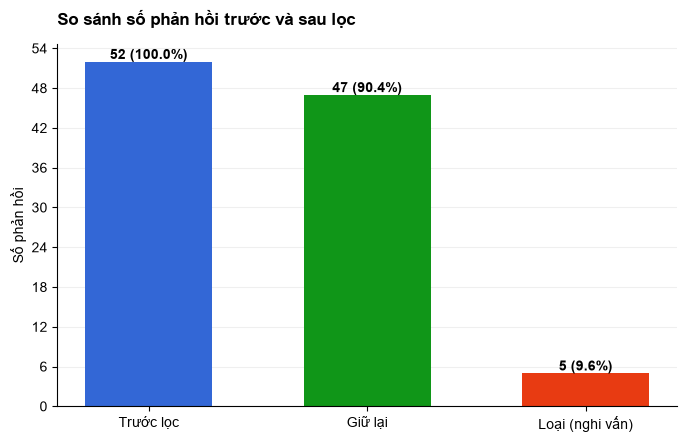

Phản hồi bị loại (xem lý do trước khi kết luận):


,Dấu thời gian,duplicate_exact,straight_lining,rapid_submission,reason
0,2026/10/16 6:43:13 CH GMT+7,False,True,False,straight_lining
48,2026/10/17 12:28:00 SA GMT+7,False,True,False,straight_lining
49,2026/10/17 12:29:17 SA GMT+7,False,True,False,straight_lining
50,2026/10/17 12:29:44 SA GMT+7,False,True,False,straight_lining
51,2026/10/17 12:30:09 SA GMT+7,False,True,False,straight_lining


5 phản hồi đầu tiên còn lại sau lọc:


,Dấu thời gian,"Từ những thông tin đã đề cập, Bạn/Anh/Chị có muốn tiếp tục tham gia khảo sát không ?",A1. Bạn đã trải nghiệm TripGuardian ở mức độ nào?,"A2. Bạn có tham gia phát triển, kiểm thử nội bộ hoặc là thành viên nhóm TripGuardian không?",A3. Bạn có quen biết thành viên nhóm thực hiện TripGuardian không?,A4. Bạn biết đến khảo sát này qua đâu?,B1. Độ tuổi,B2. Tần suất đi du lịch,B3. Bạn thường chuẩn bị lịch trình du lịch bằng cách nào?,"B4. Khi bắt đầu lập kế hoạch cho chuyến đi gần nhất, bạn đã có những thông tin nào?",...,C5. Tính khả thi cảm nhận (Perceived Feasibility) [Thứ tự tham quan phù hợp với việc di chuyển],C5. Tính khả thi cảm nhận (Perceived Feasibility) [Lịch trình có thể áp dụng cho chuyến đi thực tế],C6. Sự hài lòng (User Satisfaction) [Nhìn chung hài lòng với trải nghiệm TripGuardian],C6. Sự hài lòng (User Satisfaction) [Trải nghiệm thực tế đáp ứng kỳ vọng ban đầu],C7. Ý định sử dụng và giới thiệu (Usage & Recommendation Intentions) [Sẵn sàng tiếp tục sử dụng TripGuardian],C7. Ý định sử dụng và giới thiệu (Usage & Recommendation Intentions) [Sẵn sàng giới thiệu TripGuardian cho người khác],D1. Bạn cần chỉnh sửa lịch trình ở mức độ nào để sử dụng thực tế?,D2. Bạn đánh giá cao những điểm nào của TripGuardian?,"D3. Theo bạn, TripGuardian cần cải thiện điều gì nhất?",D4. Bạn có đề xuất nào để cải thiện TripGuardian không?
1,2026/10/16 6:50:43 CH GMT+7,Đồng ý,Đã tương tác với chatbot hoặc xem địa điểm đề ...,Không,Có,Lớp học hoặc trường học,18–24 tuổi,Thỉnh thoảng (2–3 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã có lịch trình sơ bộ và cần điều chỉnh,...,(4),(4),(3),(3),(4),(2),Chỉ cần chỉnh sửa nhỏ,Khả năng thấu hiểu nhu cầu,Khả năng thấu hiểu nhu cầu,Thêm bản đồ ngoại tuyến
2,2026/10/16 6:52:36 CH GMT+7,Đồng ý,Đã tương tác với chatbot hoặc xem địa điểm đề ...,Không,Có,Thành viên nhóm TripGuardian,18–24 tuổi,Ít khi (1 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã có danh sách địa điểm muốn đến,...,(4),(5),(4),(3),(5),(4),Cần chỉnh sửa một số phần đáng kể,Khả năng thấu hiểu nhu cầu;Hỗ trợ lựa chọn điể...,Giao diện và trải nghiệm sử dụng,nên tối ưu lại chatbot rep nhanh hơn xíu vs ch...
3,2026/10/16 6:54:36 CH GMT+7,Đồng ý,Đã tạo được ít nhất một lịch trình,Không,Có,Thành viên nhóm TripGuardian,18–24 tuổi,Thỉnh thoảng (2–3 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã chọn điểm đến nhưng chưa biết tham quan ở đâu,...,(3),(4),(3),(5),(5),(3),Cần chỉnh sửa một số phần đáng kể,Đề xuất địa điểm phù hợp;Giao diện dễ sử dụng,Khả năng chỉnh sửa lịch trình,NaN
4,2026/10/16 6:57:01 CH GMT+7,Đồng ý,Chỉ mới xem giao diện,Không,Có,Thành viên nhóm TripGuardian,18–24 tuổi,Ít khi (1 lần/năm),Sử dụng AI hoặc ứng dụng hỗ trợ tạo lịch trình,Đã có lịch trình sơ bộ và cần điều chỉnh,...,(2),(3),(4),(4),(4),(3),Không cần chỉnh sửa,Đề xuất địa điểm phù hợp;Hỗ trợ lựa chọn điểm ...,Độ tin cậy của thông tin,NaN
5,2026/10/16 6:58:36 CH GMT+7,Đồng ý,Đã tương tác với chatbot hoặc xem địa điểm đề ...,Không,Có,Lớp học hoặc trường học,18–24 tuổi,Thỉnh thoảng (2–3 lần/năm),Tham khảo lịch trình có sẵn rồi điều chỉnh the...,Đã có lịch trình sơ bộ và cần điều chỉnh,...,(4),(5),(4),(2),(4),(3),Không cần chỉnh sửa,Hỗ trợ lựa chọn điểm đến;Giao diện dễ sử dụng,Độ tin cậy của thông tin,NaN


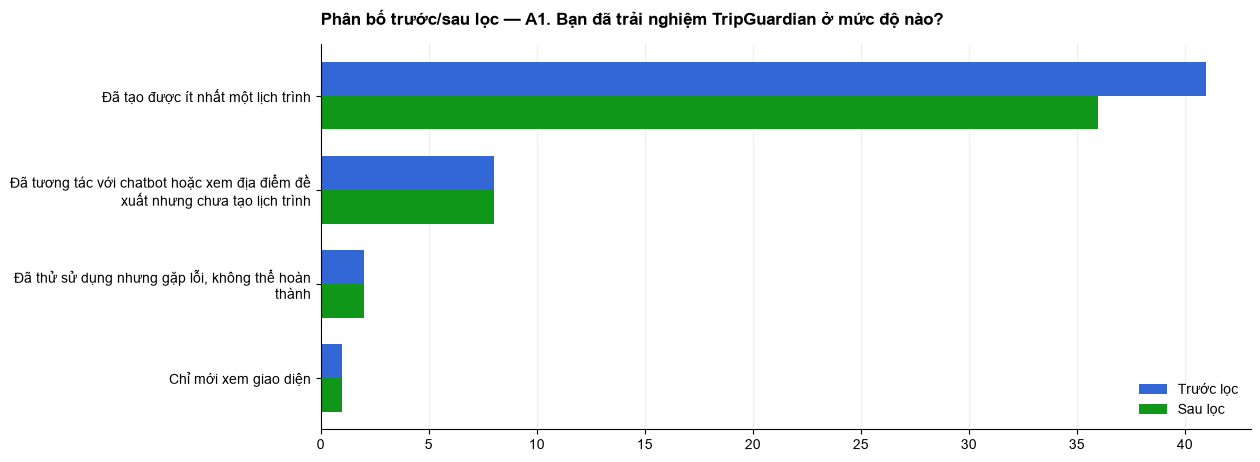

,Trước lọc,Sau lọc
A1. Bạn đã trải nghiệm TripGuardian ở mức độ nào?,,
Đã tạo được ít nhất một lịch trình,41,36
Đã tương tác với chatbot hoặc xem địa điểm đề xuất nhưng chưa tạo lịch trình,8,8
"Đã thử sử dụng nhưng gặp lỗi, không thể hoàn thành",2,2
Chỉ mới xem giao diện,1,1


In [37]:
# Tổng quan số phản hồi trước/sau lọc
comparison = pd.DataFrame({
    "Trạng thái": ["Trước lọc", "Giữ lại", "Loại (nghi vấn)"],
    "Số phản hồi": [len(raw), len(clean), int(active_flags.sum())],
    "Tỷ lệ (%)": [100, len(clean)/len(raw)*100, active_flags.mean()*100]
})
display(comparison.style.format({"Tỷ lệ (%)": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(8, 4.7), facecolor="white")
bars = ax.bar(comparison["Trạng thái"], comparison["Số phản hồi"], color=["#3367D6", "#109618", "#E83B12"], width=.58)
ax.set_title("So sánh số phản hồi trước và sau lọc", loc="left", pad=14)
ax.set_ylabel("Số phản hồi"); ax.yaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
for bar, value, rate in zip(bars, comparison["Số phản hồi"], comparison["Tỷ lệ (%)"]):
    ax.text(bar.get_x() + bar.get_width()/2, value + .4, f"{value} ({rate:.1f}%)", ha="center", fontweight="bold")
fig.savefig(OUTPUT_DIR / "before_after_filter.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# Bảng xem trước: phản hồi bị loại và phản hồi còn lại.
print("Phản hồi bị loại (xem lý do trước khi kết luận):")
display(pd.concat([raw[[timestamp_col]], audit[["duplicate_exact", "straight_lining", "rapid_submission", "reason"]]], axis=1).loc[active_flags])
print("5 phản hồi đầu tiên còn lại sau lọc:")
display(clean.head())

# Biểu đồ phân bố một câu trước/sau để kiểm tra tác động của bộ lọc.
QUESTION_FOR_COMPARISON = "A1."  # Ví dụ: "B1.", "D1." hoặc tên cột đầy đủ
selected = next((c for c in answer_cols if c.startswith(QUESTION_FOR_COMPARISON)), None)
if selected is None:
    raise ValueError(f"Không tìm thấy câu hỏi: {QUESTION_FOR_COMPARISON}")

before_counts = raw[selected].dropna().astype(str).str.strip().replace("", np.nan).dropna().value_counts()
after_counts = clean[selected].dropna().astype(str).str.strip().replace("", np.nan).dropna().value_counts()
all_choices = before_counts.index.union(after_counts.index)
compare_counts = pd.DataFrame({"Trước lọc": before_counts.reindex(all_choices, fill_value=0), "Sau lọc": after_counts.reindex(all_choices, fill_value=0)})
fig, ax = plt.subplots(figsize=(12, max(5, .6*len(all_choices)+2)), facecolor="white")
y = np.arange(len(all_choices)); h = .36
ax.barh(y-h/2, compare_counts["Trước lọc"], h, label="Trước lọc", color="#3367D6")
ax.barh(y+h/2, compare_counts["Sau lọc"], h, label="Sau lọc", color="#109618")
ax.set_yticks(y, [short(x, 48) for x in all_choices]); ax.invert_yaxis()
ax.set_title(f"Phân bố trước/sau lọc — {question_title(selected)}", loc="left", pad=14)
ax.xaxis.set_major_locator(MaxNLocator(integer=True)); ax.grid(axis="x", alpha=.2); ax.set_axisbelow(True); ax.legend(frameon=False)
fig.savefig(OUTPUT_DIR / "before_after_selected_question.png", dpi=180, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)
compare_counts


## 3. Xuất biểu đồ trước và sau lọc

Mỗi câu hỏi được xuất thành **hai ảnh**:

- `before_<mã câu>.png`: toàn bộ phản hồi gốc.
- `after_<mã câu>.png`: phản hồi còn lại sau bộ lọc.

Điều này áp dụng cả cho biểu đồ tròn/cột ngang và nhóm Likert C1–C7. Các ảnh được lưu trong `tripguardian_charts`.


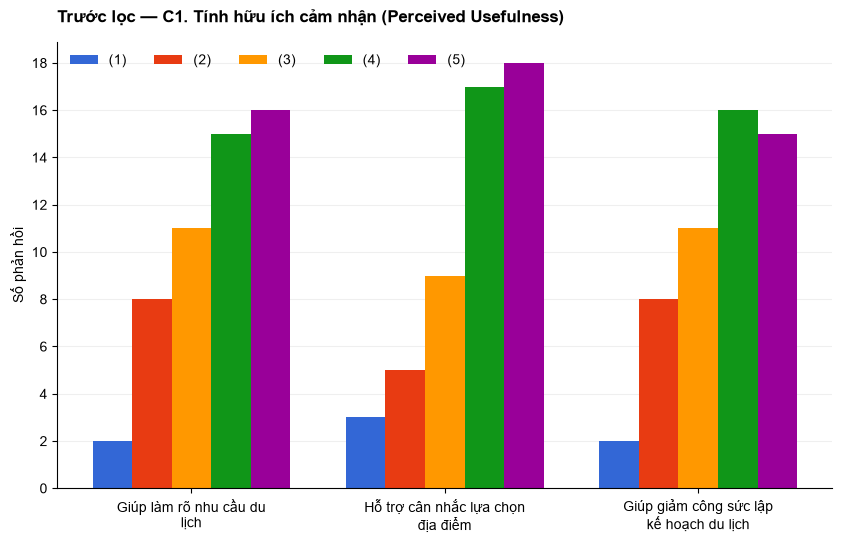

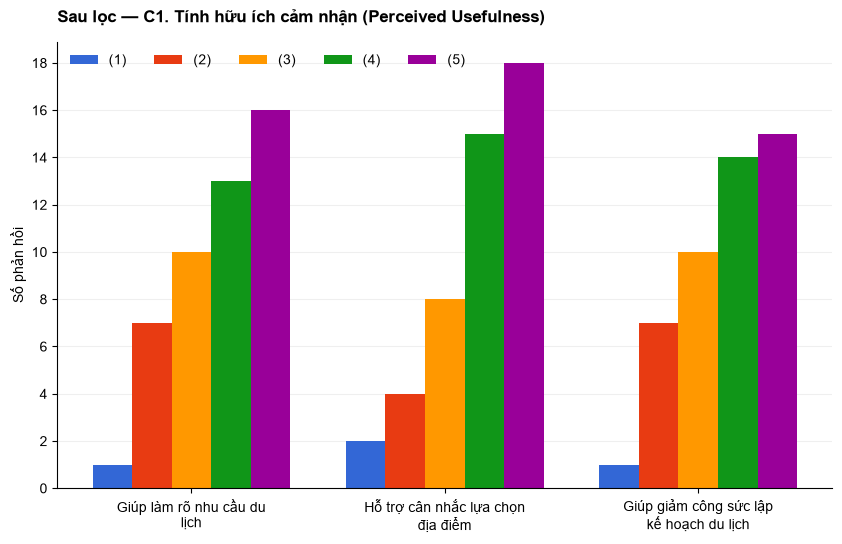

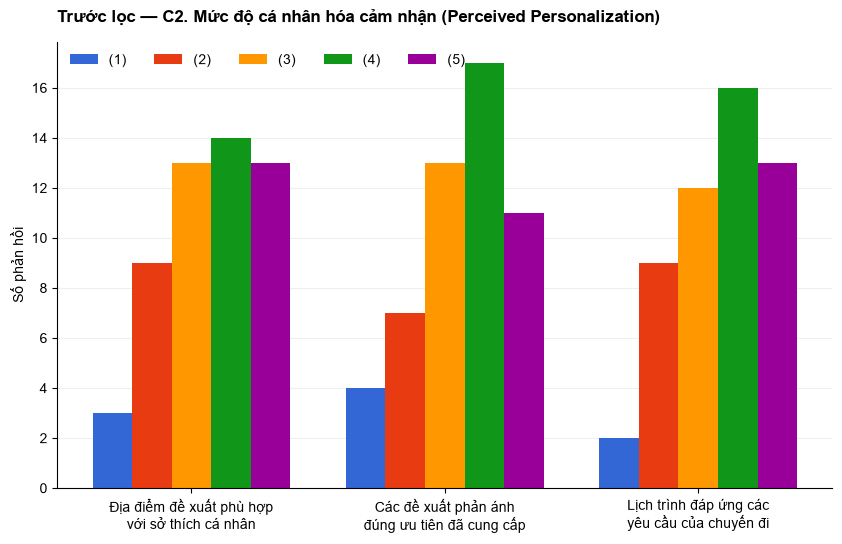

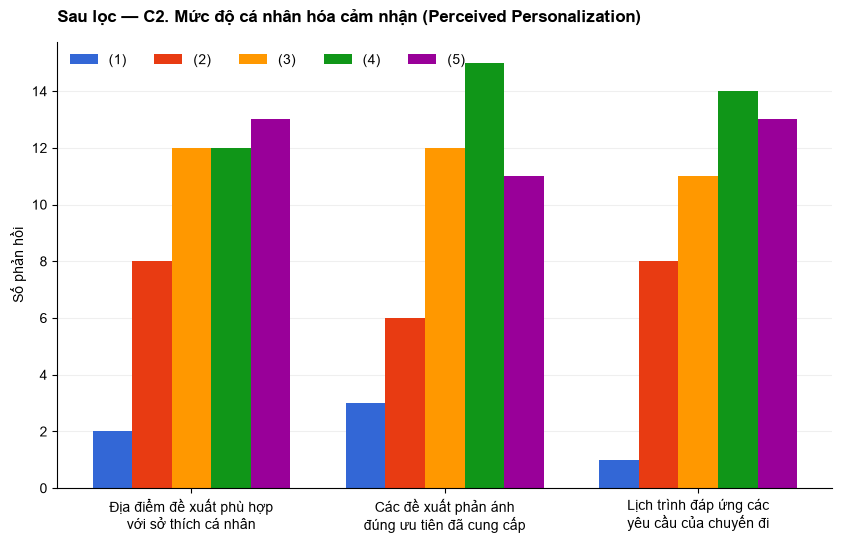

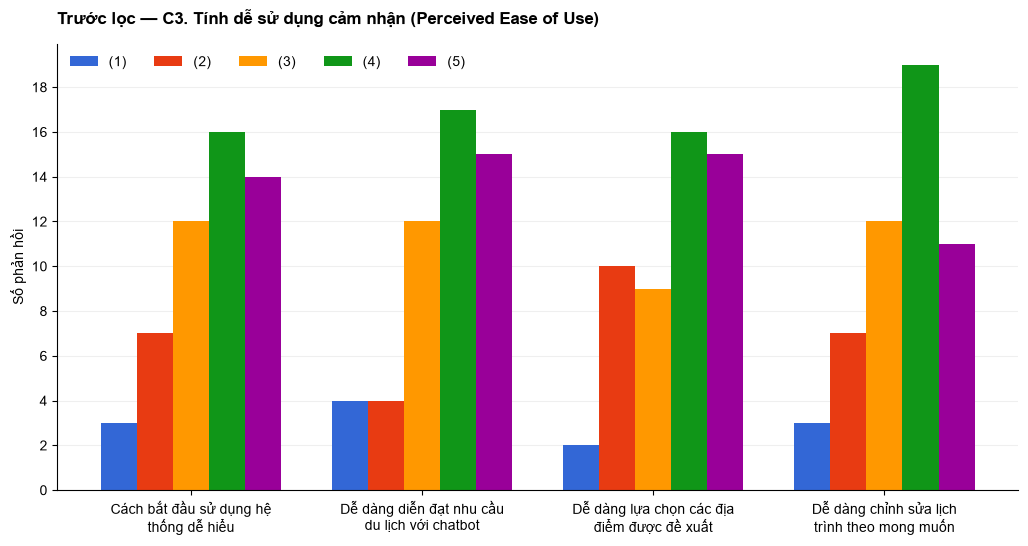

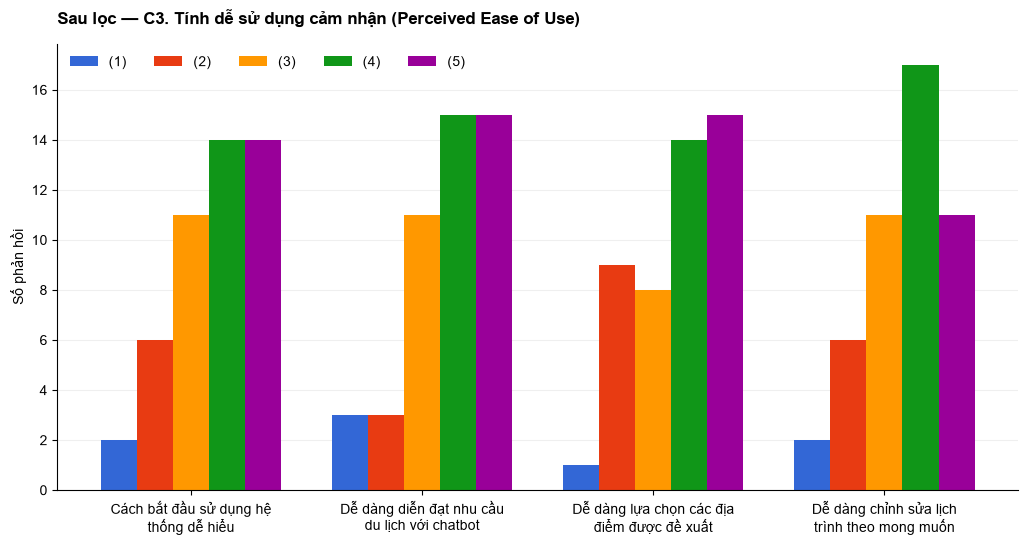

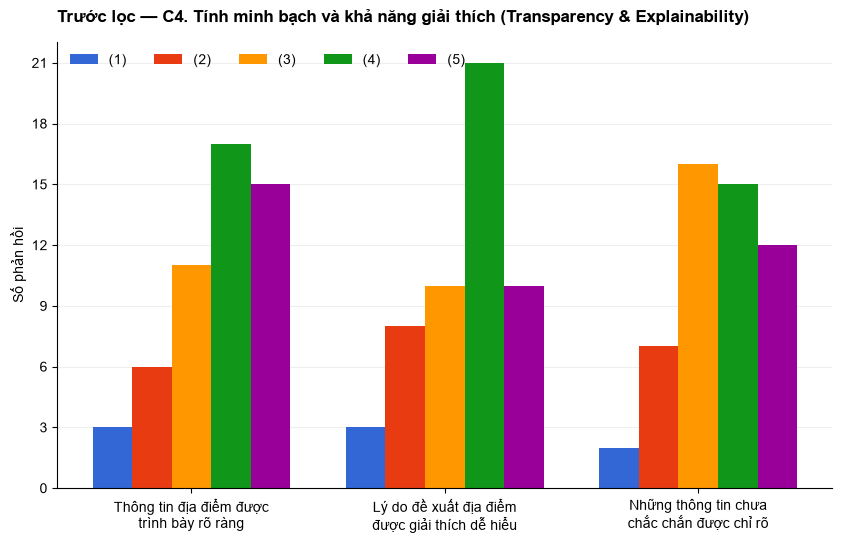

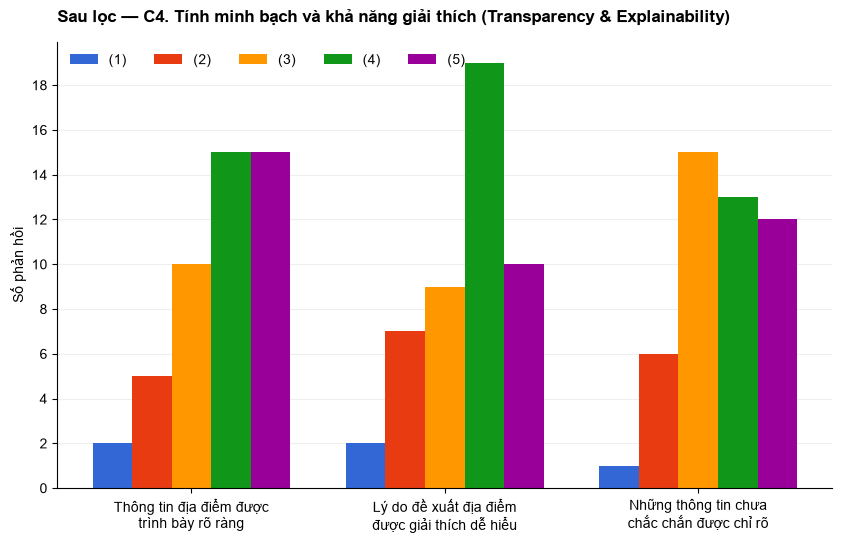

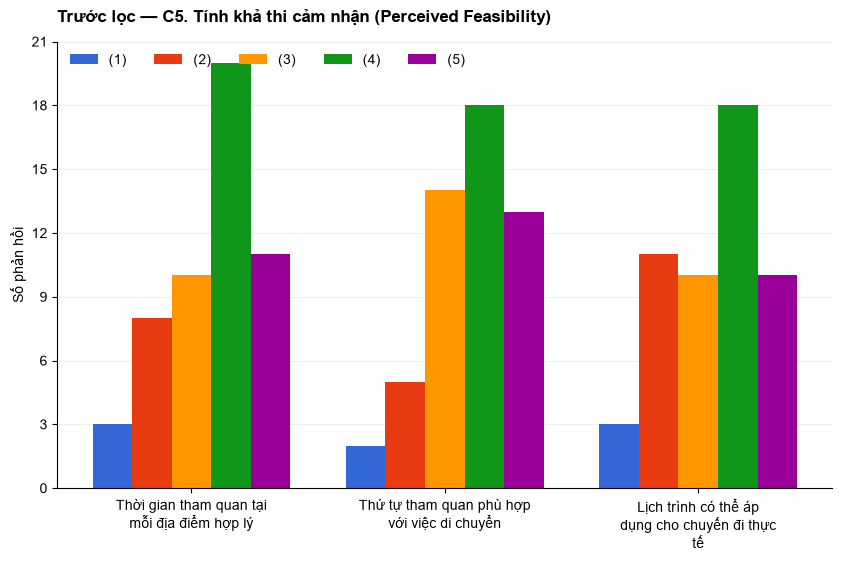

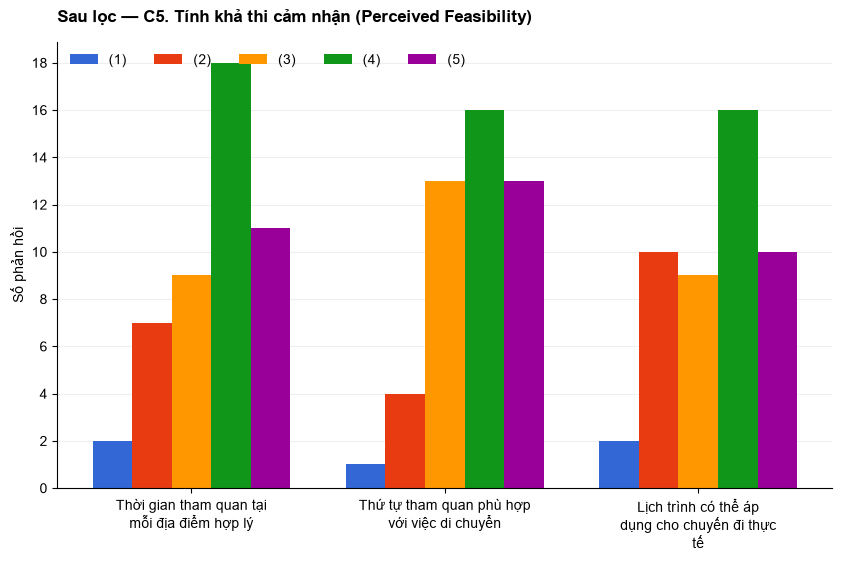

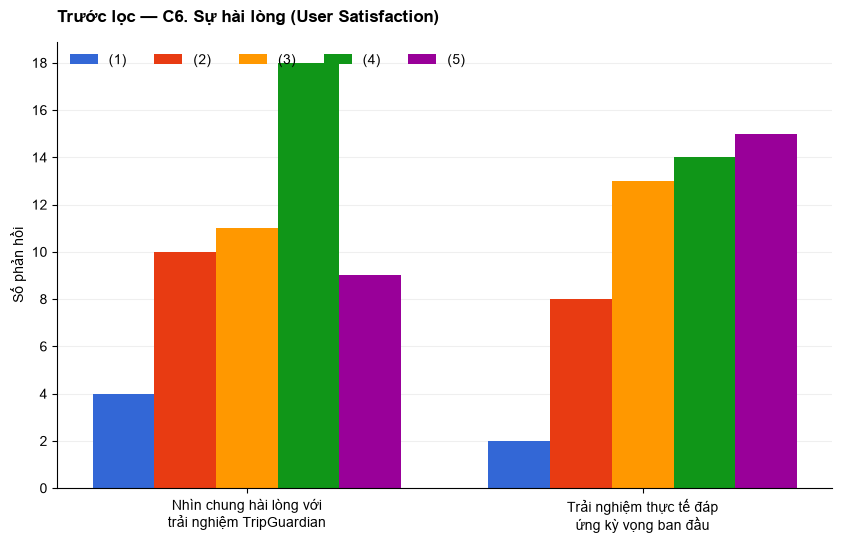

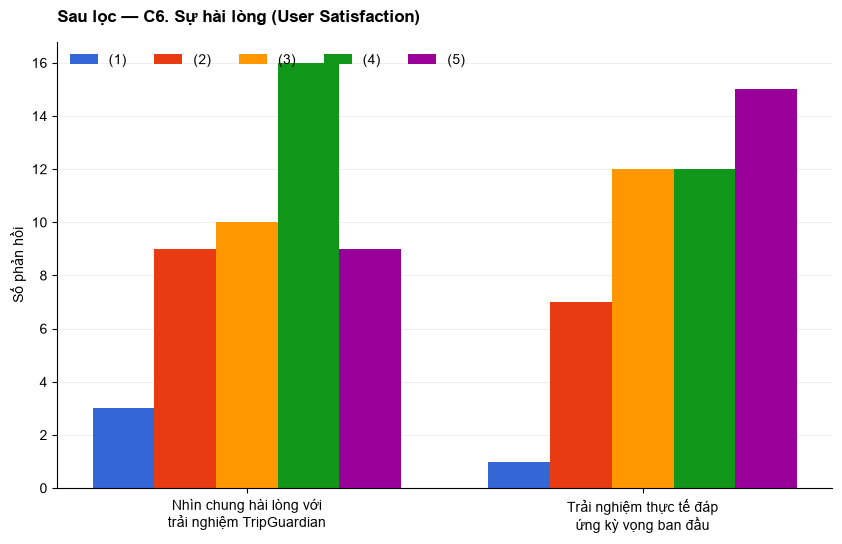

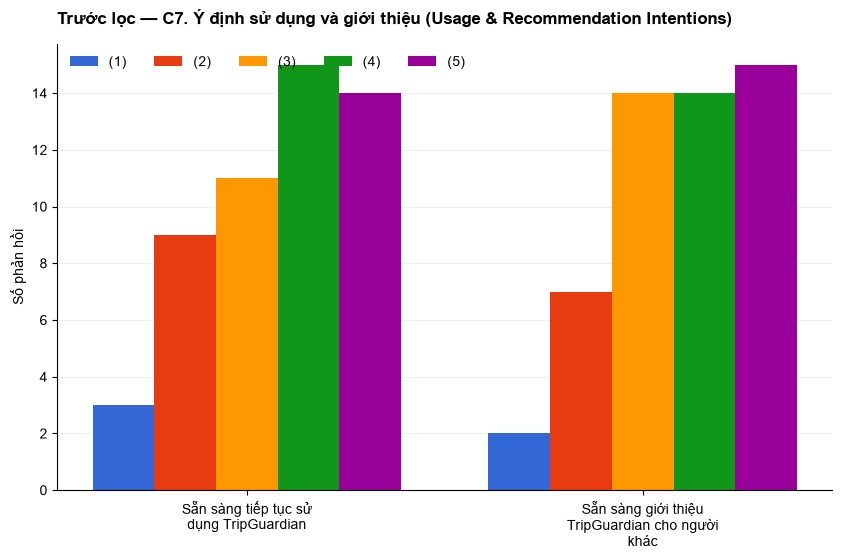

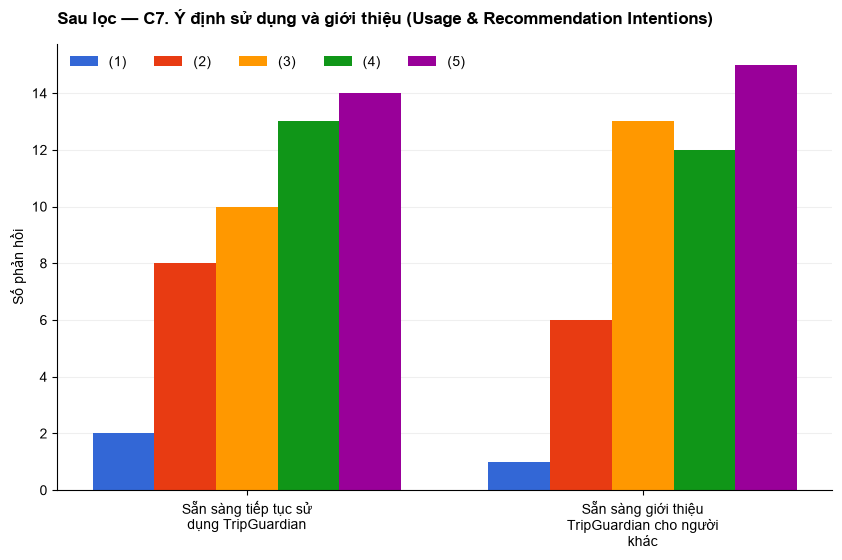

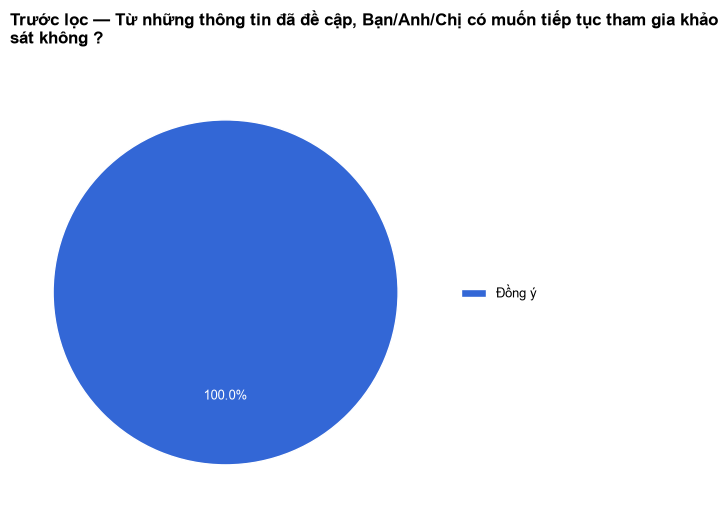

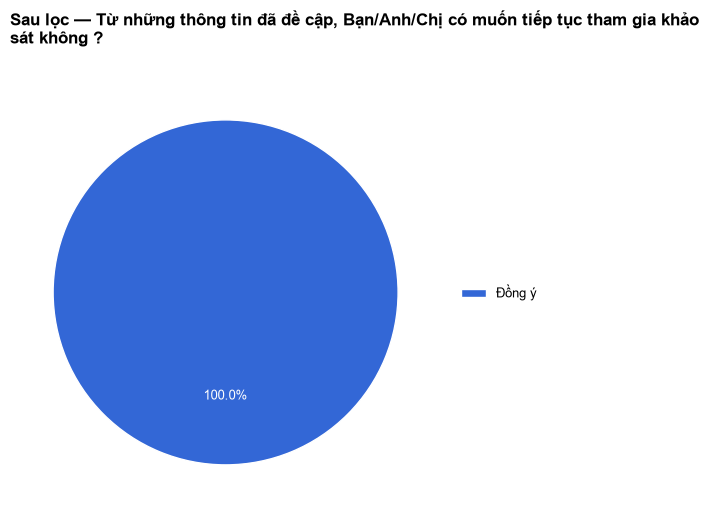

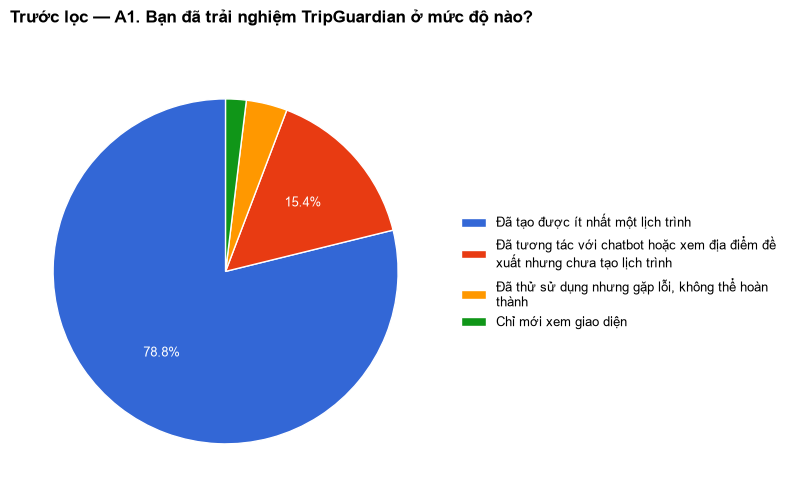

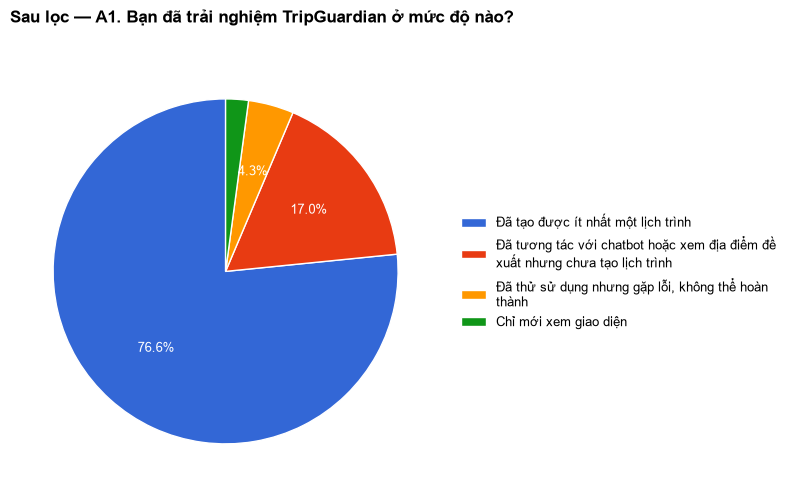

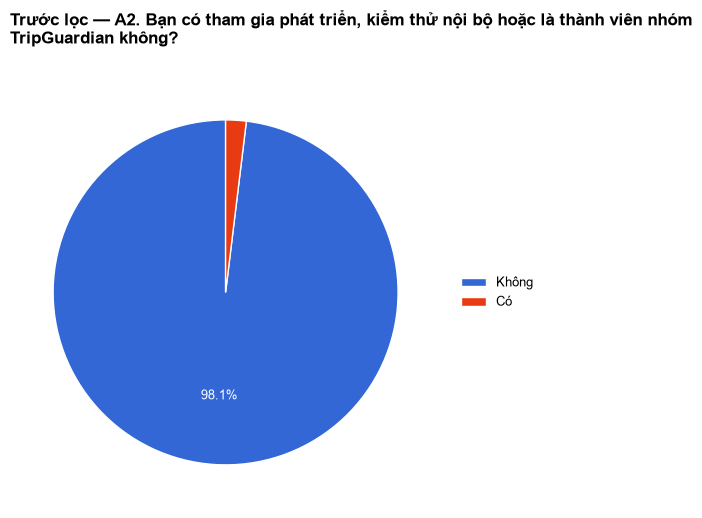

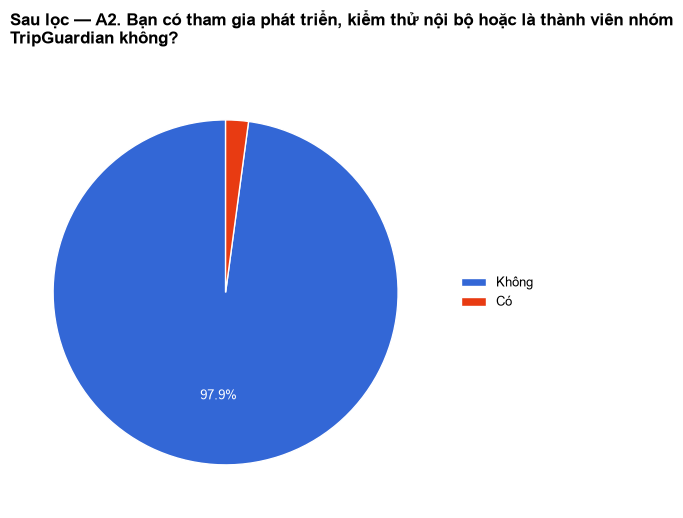

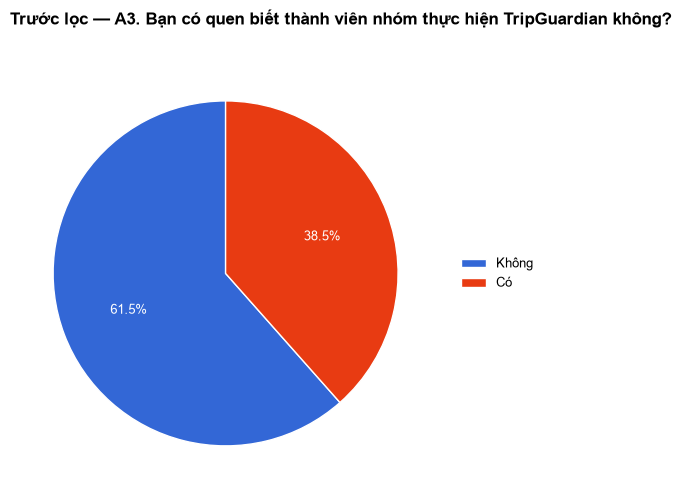

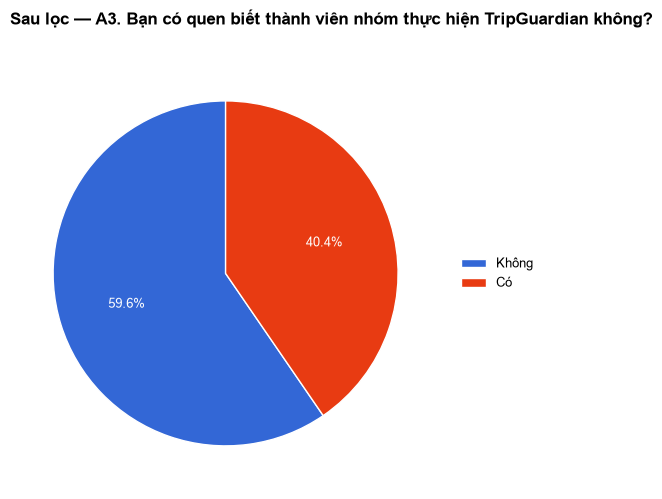

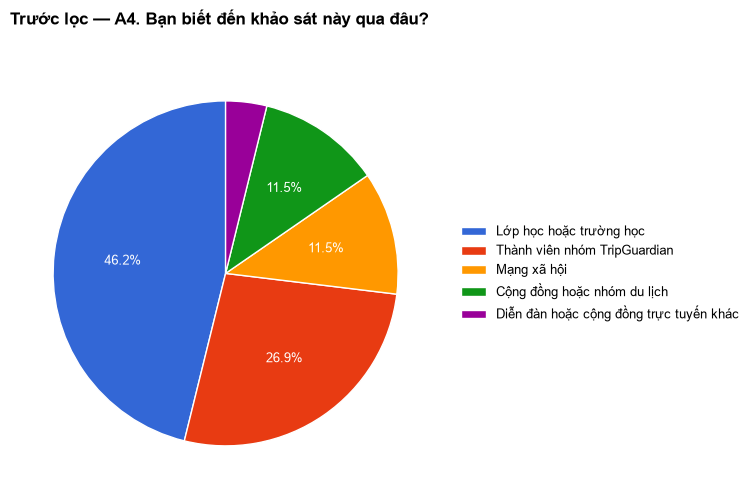

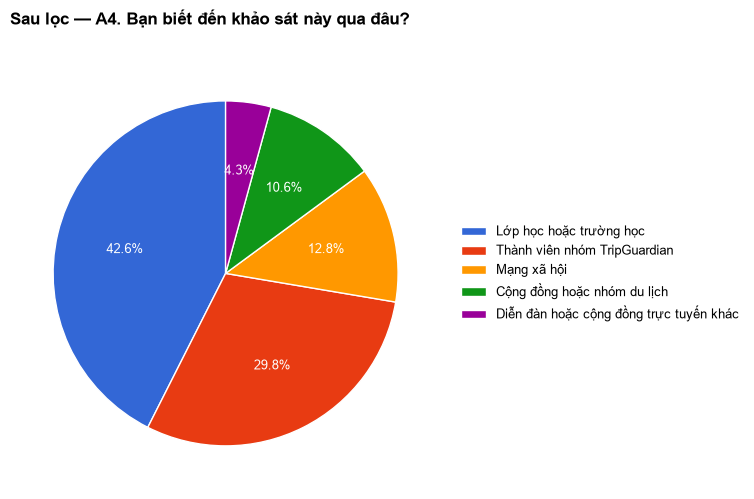

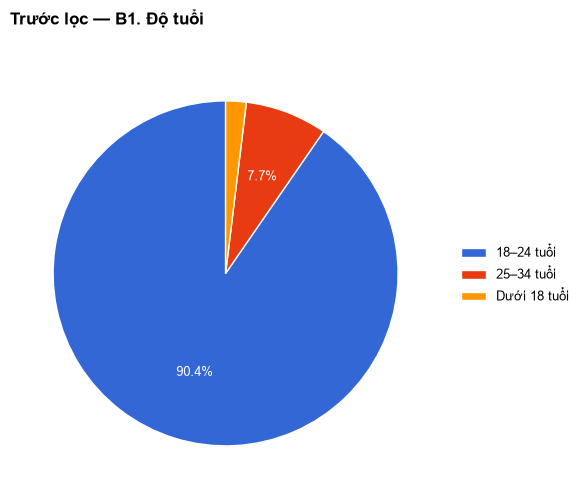

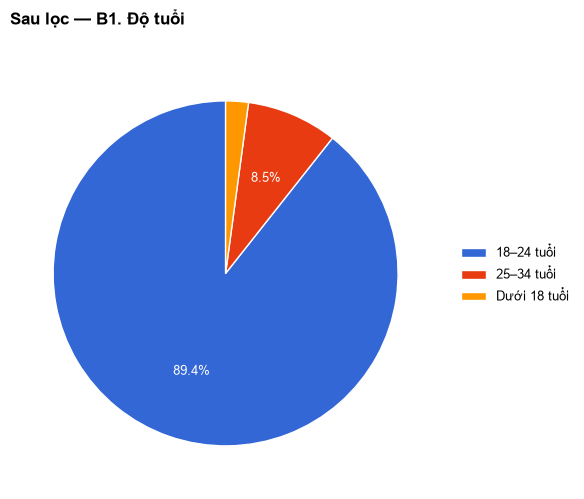

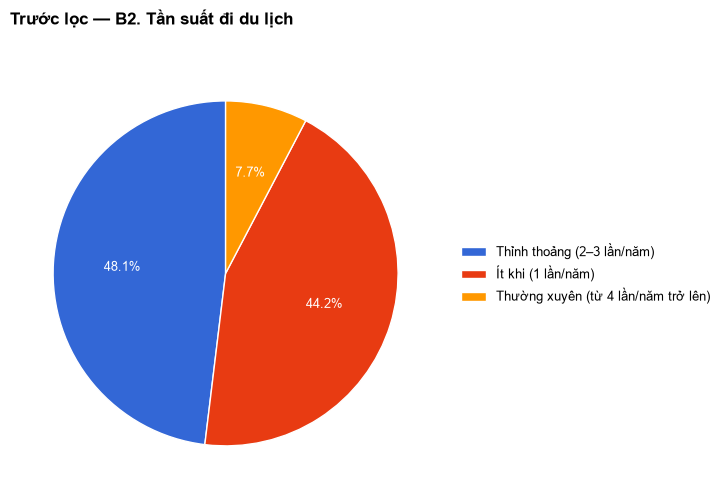

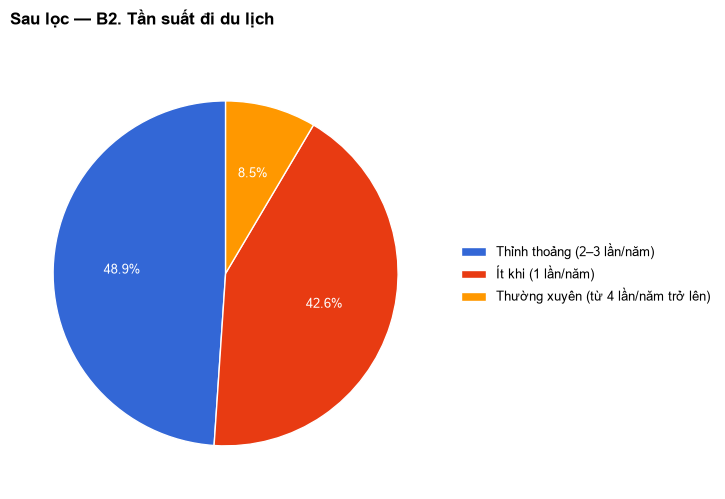

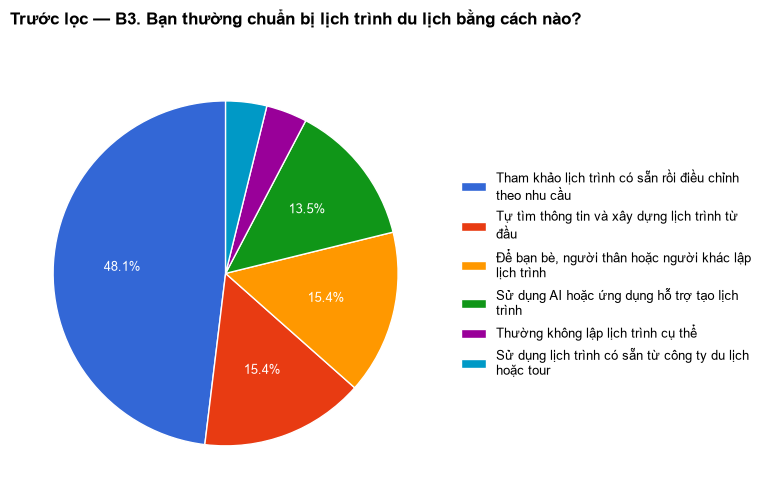

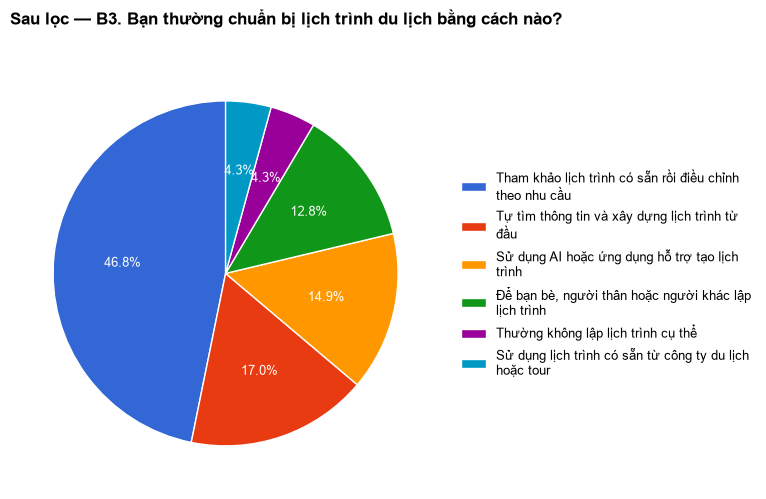

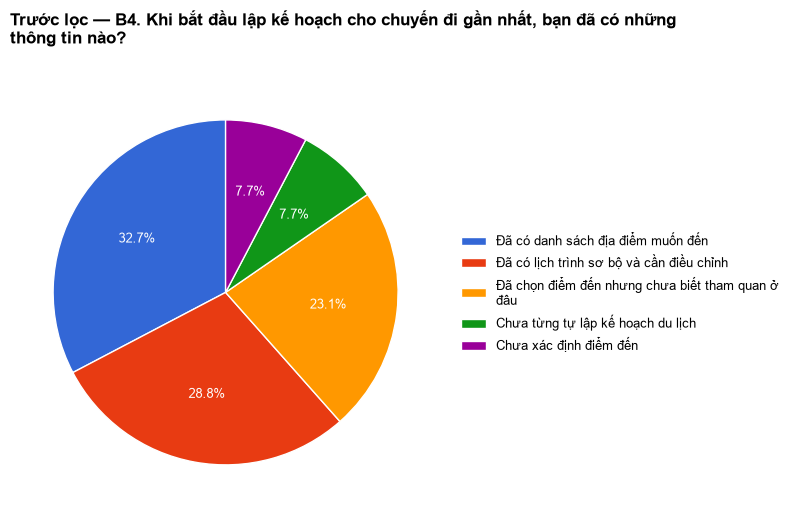

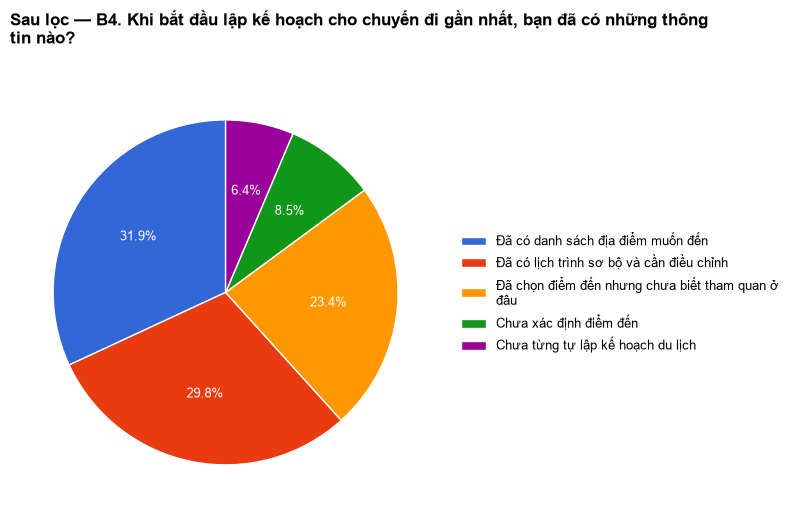

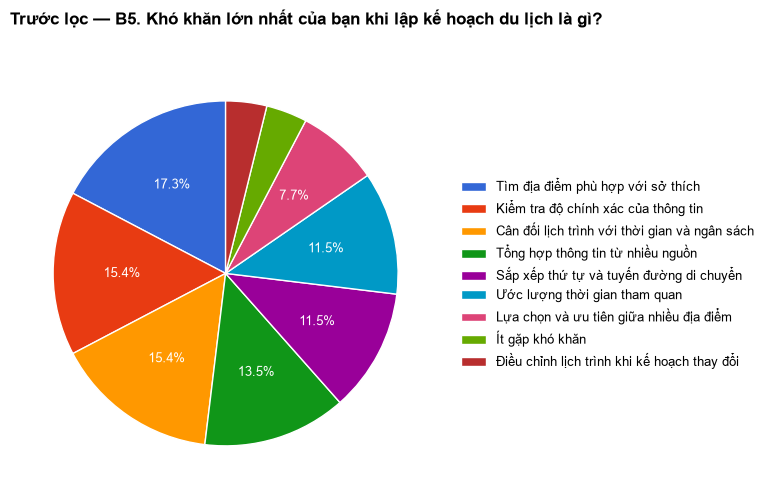

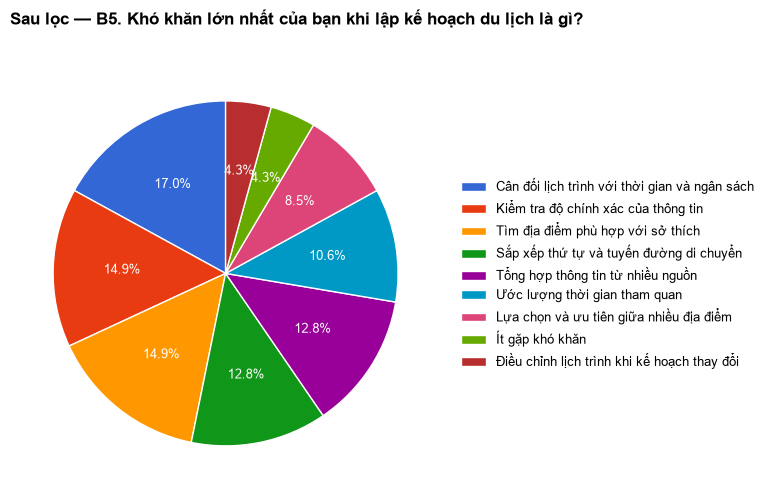

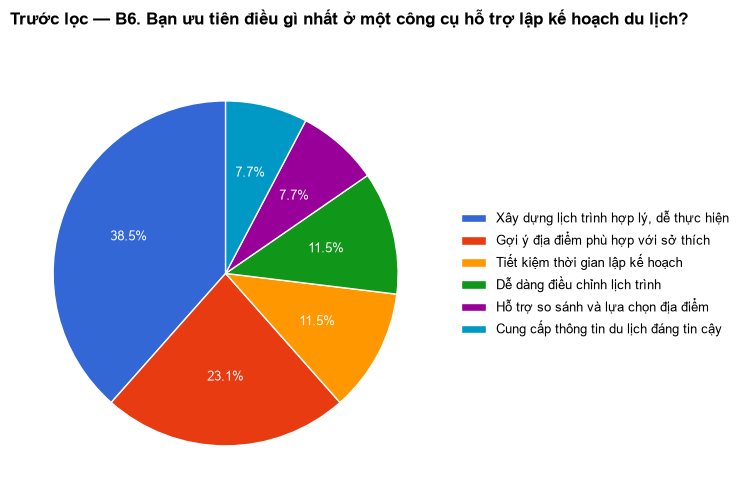

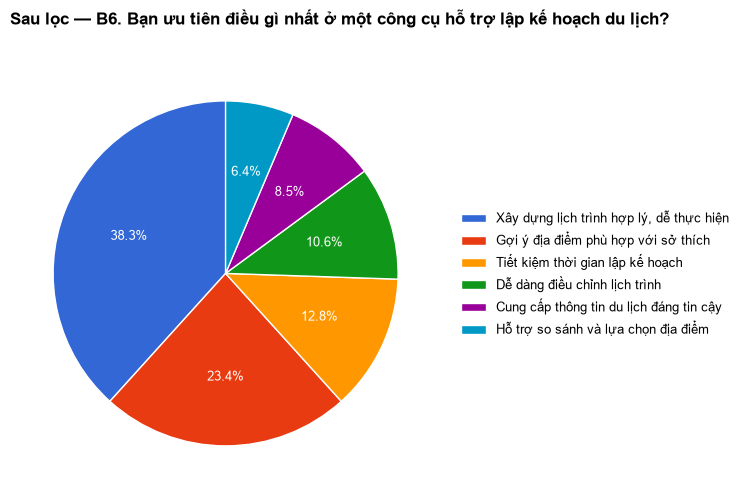

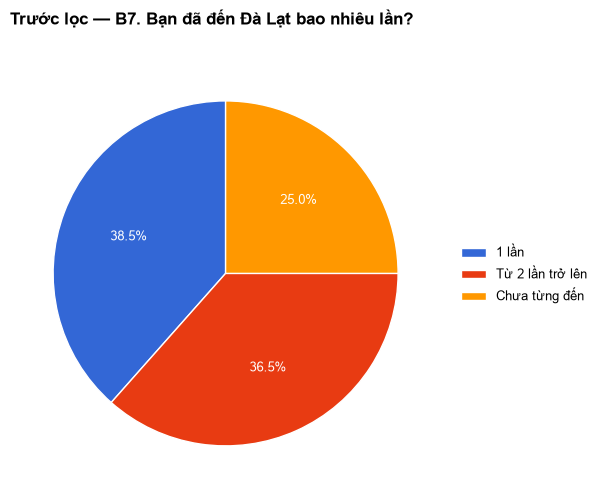

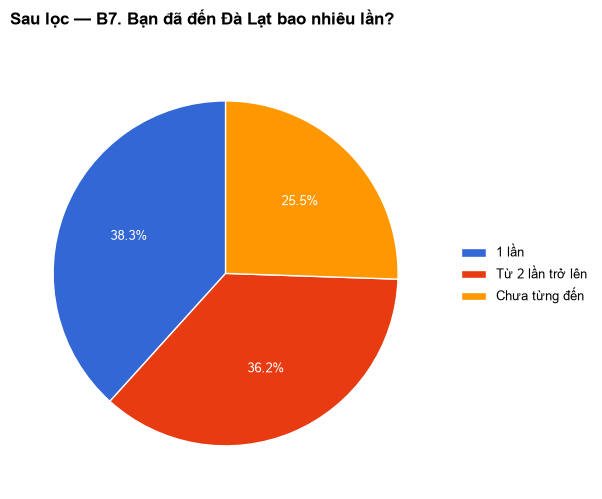

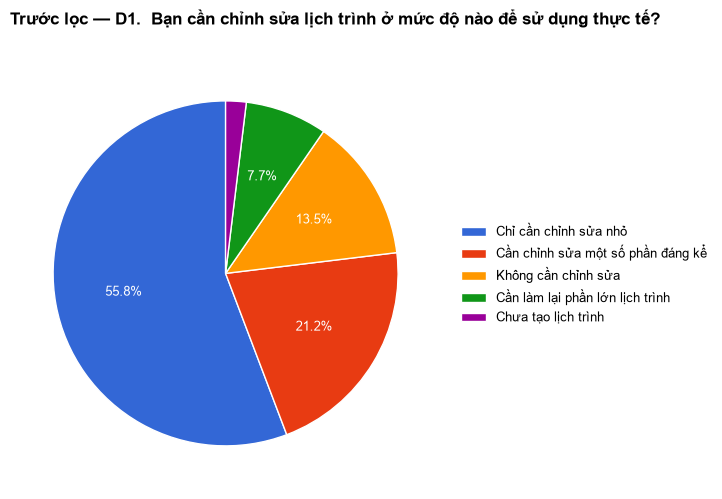

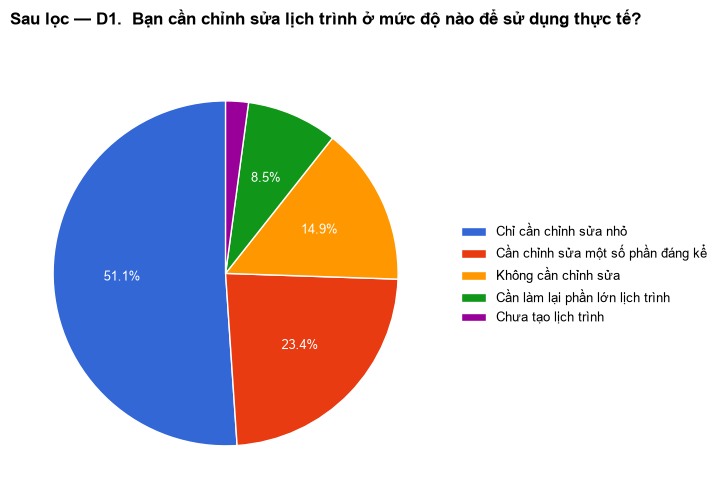

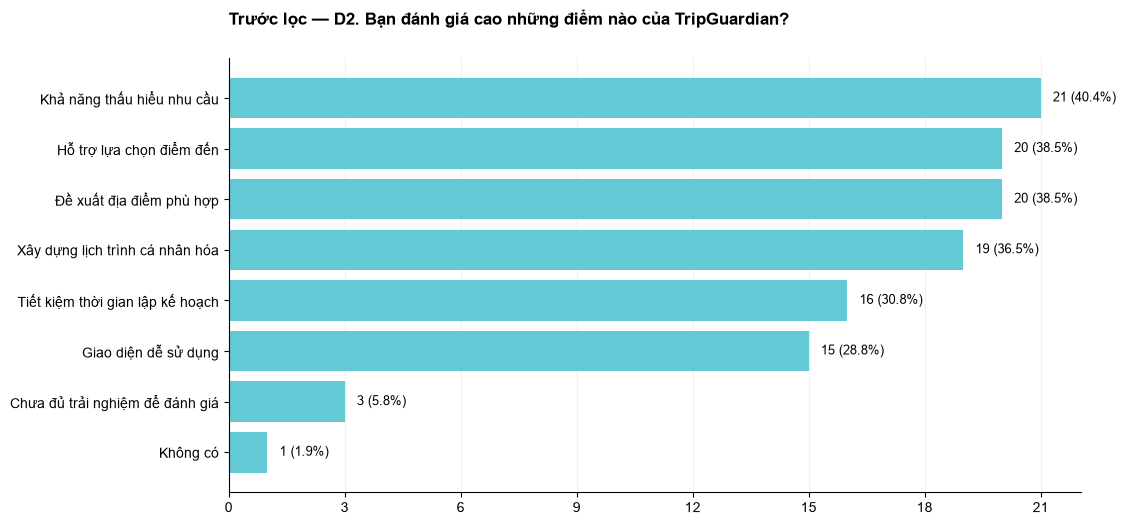

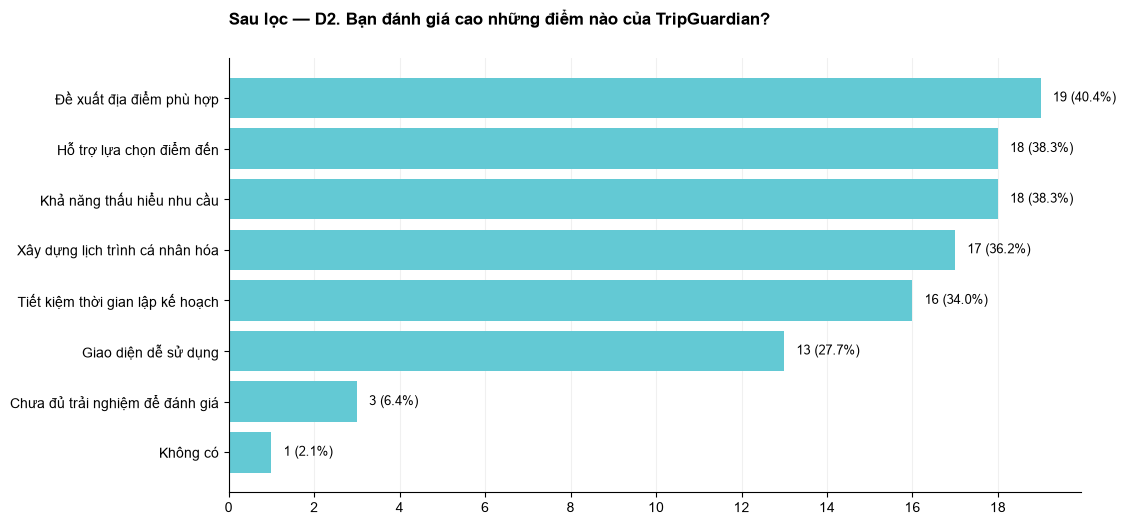

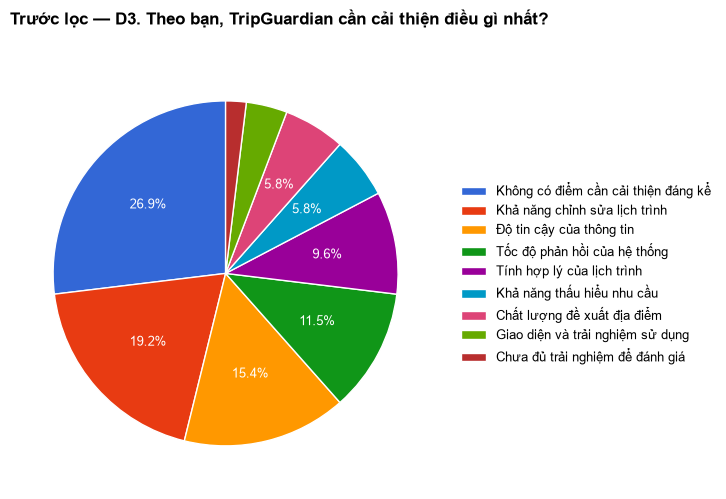

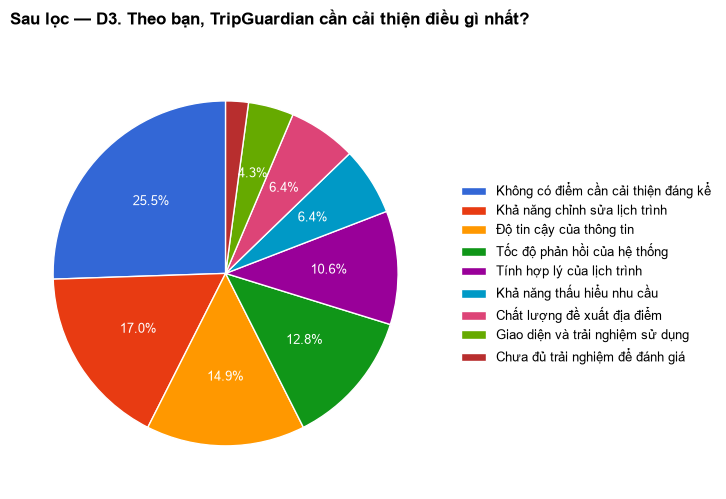

Đã lưu cặp biểu đồ trước/sau và nhật ký lọc ở: D:\cs\draft\tripguardian_charts


In [38]:
# Mỗi câu có hai biểu đồ: before_* dùng dữ liệu gốc, after_* dùng dữ liệu sau lọc.
DATASETS_TO_PLOT = {
    "before": raw.drop(columns="_timestamp", errors="ignore"),
    "after": clean,
}

# Biểu đồ Likert C1--C7 trước và sau lọc.
for group in range(1, 8):
    cols = [c for c in clean.columns if re.match(fr"^C{group}\.", c)]
    if cols:
        base_name = question_title(cols[0]).split("[")[0].strip()
        for stage, data in DATASETS_TO_PLOT.items():
            stage_label = "Trước lọc" if stage == "before" else "Sau lọc"
            likert_group(data, cols, f"{stage_label} — {base_name}", f"{stage}_C{group}_Likert")

# Các câu còn lại: vẽ cặp biểu đồ trước/sau lọc.
for i, col in enumerate(clean.columns):
    if re.match(r"^C[1-7]\.", col) or col == timestamp_col or col.startswith("D4."):
        continue
    code = re.match(r"^([A-D]\d+)\.", col)
    question_id = code.group(1) if code else f"question_{i:02d}"
    for stage, data in DATASETS_TO_PLOT.items():
        answers = data[col].dropna().astype(str)
        is_multi = answers.str.contains(";", regex=False).any()
        stage_label = "Trước lọc" if stage == "before" else "Sau lọc"
        chart_title = f"{stage_label} — {col}"
        if is_multi:
            horizontal_multi(data[col], chart_title, f"{stage}_{question_id}")
        else:
            pie_chart(data[col], chart_title, f"{stage}_{question_id}")

print(f"Đã lưu cặp biểu đồ trước/sau và nhật ký lọc ở: {OUTPUT_DIR.resolve()}")


## 4. Bảng đối chiếu cuối cùng

Dùng bảng này để đối chiếu tổng số trước/sau lọc khi viết báo cáo.


In [39]:
summary = pd.DataFrame({
    "Chỉ số": ["Phản hồi gốc", "Trùng hoàn toàn", "Chọn một mức Likert xuyên suốt", f"Gửi cách phản hồi trước ≤ {RAPID_SECONDS} giây", "Phản hồi dùng để vẽ"],
    "Số lượng": [len(raw), flags["duplicate_exact"].sum(), flags["straight_lining"].sum(), flags["rapid_submission"].sum(), len(clean)]
})
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False, encoding="utf-8-sig")
summary


,Chỉ số,Số lượng
0,Phản hồi gốc,52
1,Trùng hoàn toàn,0
2,Chọn một mức Likert xuyên suốt,5
3,Gửi cách phản hồi trước ≤ 60 giây,0
4,Phản hồi dùng để vẽ,47
